## 1. Setup ##

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from opa import steering_weights, pattern, fwhm, find_peaks

wl = 1.55e-6
d, N, theta0 = wl / 2, 64, 20   
theta = np.radians(np.linspace(-90, 90, 7201))
rng = np.random.default_rng(42)          # fixed seed so results are reproducible. Source of random errors.

## 2. What phase errors look like ##

Here we add a random phase error on each emiiter

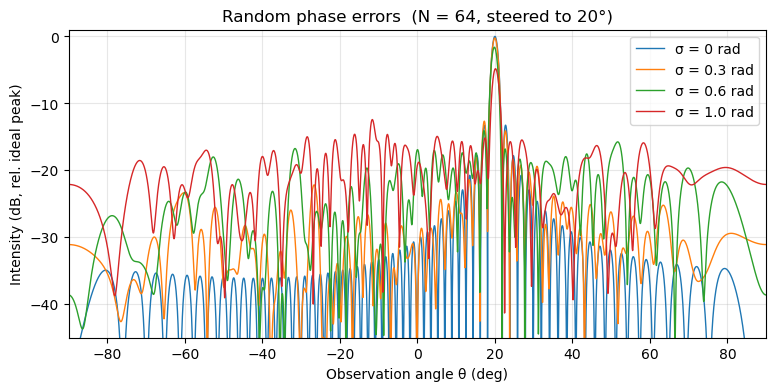

In [2]:
w0 = steering_weights(N, d, wl, theta0)

fig, ax = plt.subplots(figsize=(9, 4))
for sigma in [0, 0.3, 0.6, 1.0]:
    w = w0 * np.exp(1j * rng.normal(0, sigma, N))  # random phase error on each emitter
    I = pattern(theta, w, d, wl)
    ax.plot(np.degrees(theta), 10 * np.log10(I + 1e-12), lw=1, label=f"σ = {sigma} rad")

ax.set_ylim(-45, 1); ax.set_xlim(-90, 90)
ax.set_xlabel("Observation angle θ (deg)"); ax.set_ylabel("Intensity (dB, rel. ideal peak)")
ax.set_title(f"Random phase errors  (N = {N}, steered to {theta0}°)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

σ is the RMS phase error of each emitter relative to its intended phase, with errors independent from emitter to emitter.

Notes: 
    
The main beam gets weaker. At σ = 1 rad it drops by roughly 4 dB.
The clean sidelobe structure fills in with a ragged noise floor. At σ = 1 rad it rises to around −20 dB

## 3. Averaging over many random chips (Monte Carlo) and comparing with theory 

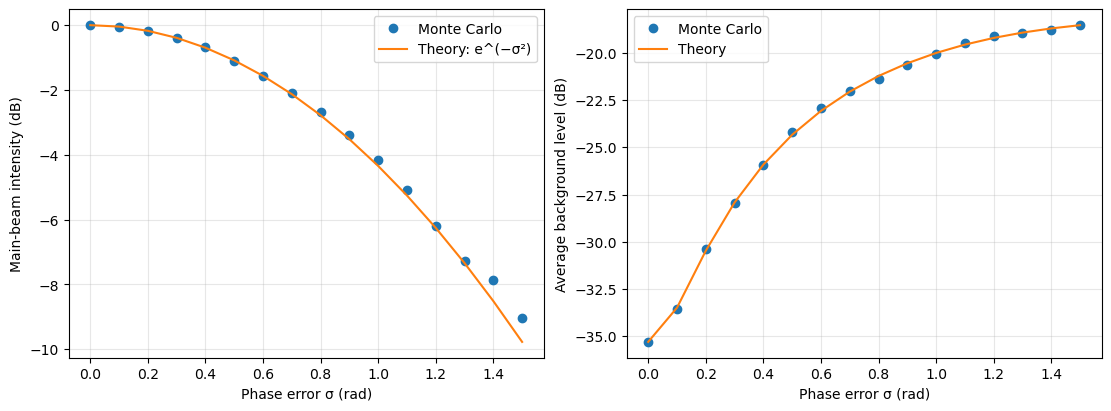

In [6]:
theta_mc = np.radians(np.linspace(-90, 90, 7201))    # coarser grid for speed
s, s0 = np.sin(theta_mc), np.sin(np.radians(theta0))
bg = np.abs(s - s0) > 5 * wl / (N * d)              # "background": well away from the beam
i0 = np.argmin(np.abs(theta_mc - np.radians(theta0)))
I_ideal = pattern(theta_mc, w0, d, wl)

sigmas = np.linspace(0, 1.5, 16)
trials = 100
peak_mc, floor_mc = [], []
for sigma in sigmas:
    pk, fl = [], []
    for _ in range(trials):
        I = pattern(theta_mc, w0 * np.exp(1j * rng.normal(0, sigma, N)), d, wl)
        pk.append(I[i0]); fl.append(I[bg].mean())
    peak_mc.append(np.mean(pk)); floor_mc.append(np.mean(fl))

g = np.exp(-sigmas ** 2)
peak_th = g
floor_th = g * I_ideal[bg].mean() + (1 - g) / N

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(sigmas, 10*np.log10(peak_mc), "o", label="Monte Carlo")
axes[0].plot(sigmas, 10*np.log10(peak_th), "-", label="Theory: e^(−σ²)")
axes[0].set_ylabel("Main-beam intensity (dB)")
axes[1].plot(sigmas, 10*np.log10(floor_mc), "o", label="Monte Carlo")
axes[1].plot(sigmas, 10*np.log10(floor_th), "-", label="Theory")
axes[1].set_ylabel("Average background level (dB)")
for ax in axes:
    ax.set_xlabel("Phase error σ (rad)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

Notes: 100 chips for each sigma from 0 to 1.5 (0.1 steps)

## 4. Turning it into a design spec

In [3]:
# --- Part 1: tolerance for 1 dB main-beam loss ---
loss_dB = 1.0
g = 10 ** (-loss_dB / 10)
sigma_max = np.sqrt(-np.log(g))
print(f"σ_max for {loss_dB} dB loss: {sigma_max:.3f} rad = {np.degrees(sigma_max):.1f}°")

# --- Part 2: noise floor at that tolerance, for several N ---
for n in [16, 64, 256, 1024]:
    print(f"  N = {n:5d}: noise floor = {10*np.log10((1 - g) / n):.1f} dB")

# --- Part 3a: thermal phase error ---
dndT = 1.8e-4                                 # silicon, per K
for L in [100e-6, 1e-3]:
    per_K = 2 * np.pi / wl * dndT * L
    print(f"L = {L*1e6:.0f} µm: {per_K:.3f} rad/K  →  tolerable ΔT ≈ {sigma_max/per_K:.2f} K")

# --- Part 3b: fabrication (order-of-magnitude) ---
dneff_dw = 1e-3                               # per nm of width, rough
L = 1e-3
print(f"1 nm width error over 1 mm: ≈ {2*np.pi/wl * dneff_dw * L:.1f} rad")

σ_max for 1.0 dB loss: 0.480 rad = 27.5°
  N =    16: noise floor = -18.9 dB
  N =    64: noise floor = -24.9 dB
  N =   256: noise floor = -31.0 dB
  N =  1024: noise floor = -37.0 dB
L = 100 µm: 0.073 rad/K  →  tolerable ΔT ≈ 6.58 K
L = 1000 µm: 0.730 rad/K  →  tolerable ΔT ≈ 0.66 K
1 nm width error over 1 mm: ≈ 4.1 rad


**Design spec.** For at most 1 dB loss in the main beam, the RMS phase error must satisfy e^{−σ²} ≥ 10^{−0.1}, giving σ ≤ 0.48 rad (≈27°). At this tolerance the scattered-light floor is (1 − e^{−σ²})/N ≈ −25 dB for N = 64, and it drops as 1/N for larger arrays.

**Physical meaning.** Silicon’s thermo-optic coefficient gives ≈0.07 rad of phase per kelvin per 100 µm at 1550 nm. So σ ≤ 0.48 rad requires temperature differences below ≈7 K over 100 µm, or ≈0.7 K over 1 mm. Fabrication is more demanding: a 1 nm waveguide-width error over 1 mm gives a phase error of order several radians, far beyond tolerance. Fabricated phased arrays therefore can’t rely on their designed phases. They must be calibrated after fabrication by measuring and correcting each emitter’s phase.

**Lay mans terms:** For a 1 mm waveguide, even a small, unintended temperature difference of about 0.7 K produces a phase error of about 0.48 rad, the most we can tolerate for 1 dB of beam loss. So long waveguides are very sensitive to stray temperature variations 

**A nuance worth getting right:** only differences between emitters matter. If the whole chip warms by 5 K uniformly, every emitter’s phase shifts by the same amount. The beam doesn’t change, because steering depends only on the phase differences between emitters. The danger is temperature differences across the chip, for example one side warmer than the other, or one heater warming its neighbours. That’s why σ is the spread of errors between emitters, and why ΔT here means the spread of temperatures between their waveguides, not the chip’s overall temperature

## 5. Amplitude tapering

**We apply tapering:** the middle emitters shine brightest, and the brightness fades smoothly towards the edges

Uniform   : FWHM = 1.59°,  strongest sidelobe = -13.3 dB
Hann taper: FWHM = 2.54°,  strongest sidelobe = -31.5 dB


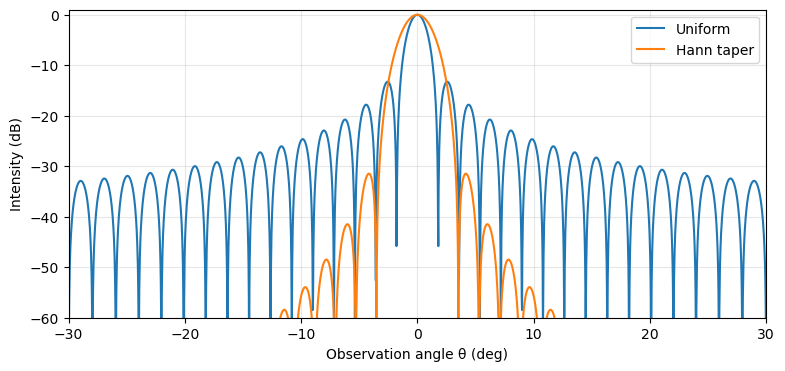

In [4]:
amp_hann = np.hanning(N + 2)[1:-1]        # taper without zero-amplitude end emitters
fig, ax = plt.subplots(figsize=(9, 4))
for name, amp in [("Uniform", None), ("Hann taper", amp_hann)]:
    I = pattern(theta, steering_weights(N, d, wl, 0, amp), d, wl)
    _, vals = find_peaks(theta, I)
    print(f"{name:10s}: FWHM = {fwhm(theta, I):.2f}°,  strongest sidelobe = {10*np.log10(np.sort(vals)[-2]):.1f} dB")
    ax.plot(np.degrees(theta), 10 * np.log10(I + 1e-12), label=name)
ax.set_ylim(-60, 1); ax.set_xlim(-30, 30)
ax.set_xlabel("Observation angle θ (deg)"); ax.set_ylabel("Intensity (dB)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

**Notes**: Trade off - tapering lowers the sidelobes a lot, but makes the main beam wider

**Why the taper widens the beam?** The faint edge emitters barely contribute, so the array effectively behaves as if it were narrower. From Part 3, a narrower array gives a wider beam, since FWHM ∝ λ/(array width)

**With equal total power:**

Uniform   : peak = 1.000 (+0.00 dB),  theory = +0.00 dB,  total power = 0.03125
Hann taper: peak = 0.677 (-1.69 dB),  theory = -1.69 dB,  total power = 0.03125


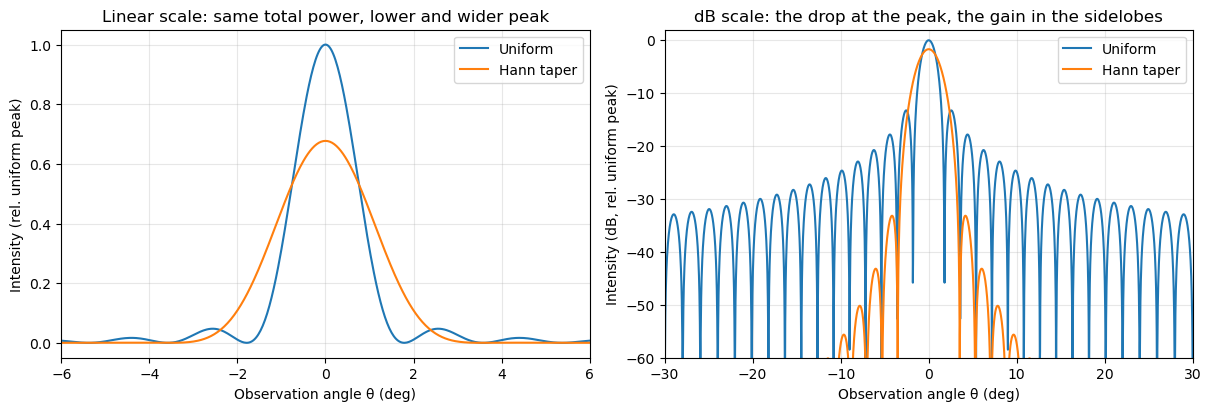

In [5]:
def pattern_equal_power(theta, amp, d, wl):
    """Far-field intensity with the emitters' total power fixed to N
    (the same as N unit-amplitude emitters), relative to the uniform array's peak."""
    N = len(amp)
    a = amp * np.sqrt(N / np.sum(amp ** 2))          # rescale so Σ a² = N
    n = np.arange(N)
    af = np.exp(1j * 2 * np.pi / wl * d * np.outer(np.sin(theta), n)) @ a
    return np.abs(af) ** 2 / N ** 2                  # uniform array peaks at exactly 1

cases = [("Uniform", np.ones(N)), ("Hann taper", amp_hann)]
s = np.sin(theta)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, amp in cases:
    I = pattern_equal_power(theta, amp, d, wl)
    total = np.sum(0.5 * (I[1:] + I[:-1]) * np.diff(s))       # total power radiated
    theory = np.sum(amp) ** 2 / (N * np.sum(amp ** 2))         # taper efficiency
    print(f"{name:10s}: peak = {I.max():.3f} ({10*np.log10(I.max()):+.2f} dB),  "
          f"theory = {10*np.log10(theory):+.2f} dB,  total power = {total:.5f}")
    axes[0].plot(np.degrees(theta), I, label=name)
    axes[1].plot(np.degrees(theta), 10 * np.log10(I + 1e-12), label=name)

axes[0].set_xlim(-6, 6); axes[0].set_ylabel("Intensity (rel. uniform peak)")
axes[0].set_title("Linear scale: same total power, lower and wider peak")
axes[1].set_xlim(-30, 30); axes[1].set_ylim(-60, 2); axes[1].set_ylabel("Intensity (dB, rel. uniform peak)")
axes[1].set_title("dB scale: the drop at the peak, the gain in the sidelobes")
for ax in axes:
    ax.set_xlabel("Observation angle θ (deg)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Notes:** It redistributes the light: less into the sidelobes, and the main beam made wider and about 1.8 dB lower at its peak. The peak drops because the beam’s peak field adds the emitters’ amplitudes (Σa), while the power cost is Σa². A uniform distribution maximises the peak for a given power

Tapering the emitter amplitudes with a Hann window lowers the strongest sidelobe from −13 dB to about −31 dB, because removing the sharp edges of the illumination removes the ringing in its Fourier transform, the far field. The cost is a main beam about 1.6× wider, because the faint edge emitters make the array effectively narrower, plus about 1.8 dB less peak power for the same total laser power. For LIDAR, the lower sidelobes reduce ghost detections from bright reflectors, at the expense of angular resolution and range.

## Efficiency: phase errors and tapering

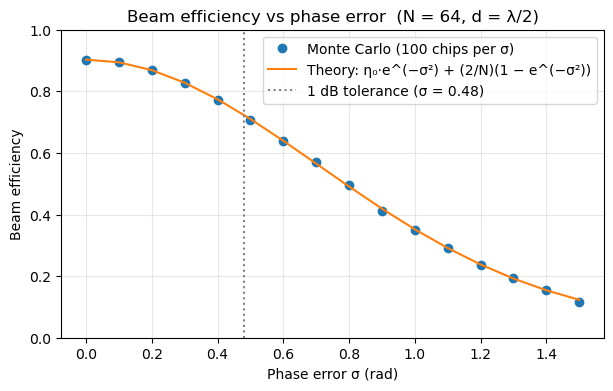

Total power: ideal 0.031250, with σ = 1 errors 0.031250


In [3]:
import importlib, opa; importlib.reload(opa)
from opa import power_budget

x64 = np.arange(N) * d                       # N = 64, d = λ/2 from the top of this notebook
sig_e = np.linspace(0, 1.5, 16)
trials_e = 100

eff_mc = []
for s in sig_e:
    effs = [power_budget(x64, wl, 0, amp=np.exp(1j * rng.normal(0, s, N)))["beam_eff"]
            for _ in range(trials_e)]
    eff_mc.append(np.mean(effs))

eff0 = power_budget(x64, wl, 0)["beam_eff"]
g = np.exp(-sig_e ** 2)
eff_th = eff0 * g + (2 / N) * (1 - g)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sig_e, eff_mc, "o", label="Monte Carlo (100 chips per σ)")
ax.plot(sig_e, eff_th, "-", label="Theory: η₀·e^(−σ²) + (2/N)(1 − e^(−σ²))")
ax.axvline(0.48, color="grey", ls=":", label="1 dB tolerance (σ = 0.48)")
ax.set_xlabel("Phase error σ (rad)"); ax.set_ylabel("Beam efficiency")
ax.set_ylim(0, 1); ax.set_title(f"Beam efficiency vs phase error  (N = {N}, d = λ/2)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

# conservation check: phase errors move light around but don't change the total
noisy = power_budget(x64, wl, 0, amp=np.exp(1j * rng.normal(0, 1.0, N)))
print(f"Total power: ideal {power_budget(x64, wl, 0)['total']:.6f}, with σ = 1 errors {noisy['total']:.6f}")

**Tapering efficiencies:**

Uniform : beam efficiency 0.9029   peak efficiency 1.000 (+0.00 dB)
Hamming : beam efficiency 0.9996   peak efficiency 0.726 (-1.39 dB)
Hann    : beam efficiency 0.9995   peak efficiency 0.677 (-1.69 dB)


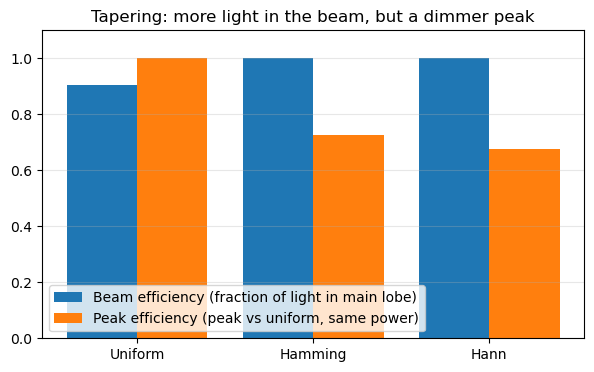

In [4]:
trap = lambda y, x: np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x))

def beam_eff_own_lobe(pb):
    """Beam efficiency with the main lobe taken out to its own first minima."""
    u, I = pb["u"], pb["I"]
    l = r = np.argmin(np.abs(u))                     # start at the beam centre (u = 0)
    while r < len(I) - 1 and I[r + 1] < I[r]:        # walk right until intensity starts rising
        r += 1
    while l > 0 and I[l - 1] < I[l]:                 # walk left likewise
        l -= 1
    return trap(I[l:r + 1], u[l:r + 1]) / pb["total"]

tapers = {"Uniform": np.ones(N), "Hamming": np.hamming(N), "Hann": np.hanning(N + 2)[1:-1]}
names, beam_effs, peak_effs = [], [], []
for name, a in tapers.items():
    pb = power_budget(x64, wl, 0, amp=a)
    beam = beam_eff_own_lobe(pb)
    peak = np.sum(a) ** 2 / (N * np.sum(a ** 2))     # peak vs uniform, same total power
    names.append(name); beam_effs.append(beam); peak_effs.append(peak)
    print(f"{name:8s}: beam efficiency {beam:.4f}   peak efficiency {peak:.3f} ({10*np.log10(peak):+.2f} dB)")

xpos = np.arange(len(names))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(xpos - 0.2, beam_effs, 0.4, label="Beam efficiency (fraction of light in main lobe)")
ax.bar(xpos + 0.2, peak_effs, 0.4, label="Peak efficiency (peak vs uniform, same power)")
ax.set_xticks(xpos); ax.set_xticklabels(names); ax.set_ylim(0, 1.1)
ax.set_title("Tapering: more light in the beam, but a dimmer peak")
ax.legend(loc="lower left"); ax.grid(alpha=0.3, axis="y"); plt.show()

**Comparing uniform vs tapering:**


**Large targets that fill the beam (e.g. a wall, a truck):** all of the main lobe hits the target, so beam efficiency matters. Tapering helps slightly. With range ∝ √(power), going from 0.90 to 0.99 is about +5% range.

**Small or distant targets, smaller than the spot (e.g. a pedestrian far away):** only the light near the beam centre hits, so peak efficiency matters. Tapering hurts. For these targets the returned power falls roughly as 1/R⁴, so range ∝ (power)^¼. A Hann peak efficiency of 0.67 gives about −10% range.

**Ghost detections** depend on the strongest sidelobe, not the total. That’s where tapering’s −13 dB → −31 dB improvement really pays off.


**Notes:**

**Phase errors leak light out of the beam** following η ≈ η₀ e^{−σ²} + (2/N)(1 − e^{−σ²}). At the 1 dB tolerance (σ = 0.48), beam efficiency drops from 0.90 to about 0.72. Total power is conserved: the light is scattered into the background, not lost.

**Tapering raises beam efficiency (about 0.90 → 0.99+) but lowers peak efficiency (1.0 → about 0.67 for Hann).** Report both, because they lead to opposite conclusions.

**Which one matters depends on the target:** beam efficiency for large targets, peak efficiency for small, distant ones, and the strongest sidelobe for ghost detections.

**Method note:** the main lobe must be measured out to its own first minima. A fixed window based on the uniform array’s null would cut the wider tapered lobes in half. That’s worth one sentence, because it shows you checked your definitions.
